
## 1. Import Libraries & Load Dataset

Import the Python libraries.

Then load the train file as a pandas DataFrame.

Each row represents one operating cycle of an engine, containing its ID, cycle number, operating settings, and 21 sensor measurements.


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

columns = (
    ["engine_id", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

train = pd.read_csv(
    "../data/train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

print("Dataset dimensions:", train.shape)
print("Number of engines:", train["engine_id"].nunique())

display(train.head(10))

Dataset dimensions: (20631, 26)
Number of engines: 100


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044
5,1,6,-0.0043,-0.0001,100.0,518.67,642.10,1584.47,1398.37,14.62,...,521.68,2388.03,8132.85,8.4108,0.03,391,2388,100.0,38.98,23.3669
6,1,7,0.0010,0.0001,100.0,518.67,642.48,1592.32,1397.77,14.62,...,522.32,2388.03,8132.32,8.3974,0.03,392,2388,100.0,39.10,23.3774
7,1,8,-0.0034,0.0003,100.0,518.67,642.56,1582.96,1400.97,14.62,...,522.47,2388.03,8131.07,8.4076,0.03,391,2388,100.0,38.97,23.3106
8,1,9,0.0008,0.0001,100.0,518.67,642.12,1590.98,1394.80,14.62,...,521.79,2388.05,8125.69,8.3728,0.03,392,2388,100.0,39.05,23.4066
9,1,10,-0.0033,0.0001,100.0,518.67,641.71,1591.24,1400.46,14.62,...,521.79,2388.06,8129.38,8.4286,0.03,393,2388,100.0,38.95,23.4694



## 3. Calculate Remaining Useful Life (RUL)

Calculate the number of operating cycles remaining before each training engine reaches its simulated failure endpoint.

$$
RUL = T_{\mathrm{failure}} - t
$$

Where:
- $T_{\mathrm{failure}}$ is the engine's final operating cycle.
- $t$ is the current operating cycle.

RUL is the dependent variable in our regression model.

In [3]:

# Calculate the maximum recorded cycle for each engine
train["max_cycle"] = (
    train.groupby("engine_id")["cycle"].transform("max")
)

# Calculate Remaining Useful Life
train["RUL"] = train["max_cycle"] - train["cycle"]

# Inspect Engine 1
display(
    train.loc[
        train["engine_id"] == 1,
        ["engine_id", "cycle", "max_cycle", "RUL"]
    ].head(10)
)

# Inspect the final observation for Engine 1
display(
    train.loc[
        train["engine_id"] == 1,
        ["engine_id", "cycle", "max_cycle", "RUL"]
    ].tail(1)
)


,engine_id,cycle,max_cycle,RUL
0,1,1,192,191
1,1,2,192,190
2,1,3,192,189
3,1,4,192,188
4,1,5,192,187
5,1,6,192,186
6,1,7,192,185
7,1,8,192,184
8,1,9,192,183
9,1,10,192,182


,engine_id,cycle,max_cycle,RUL
191,1,192,192,0



## 4. Engine Lifetime Distribution

Calculate descriptive statistics and plot the distribution of engine lifetimes.

This helps us understand the average engine lifetime and the variability between engines.


Engine lifetime descriptive statistics:


count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

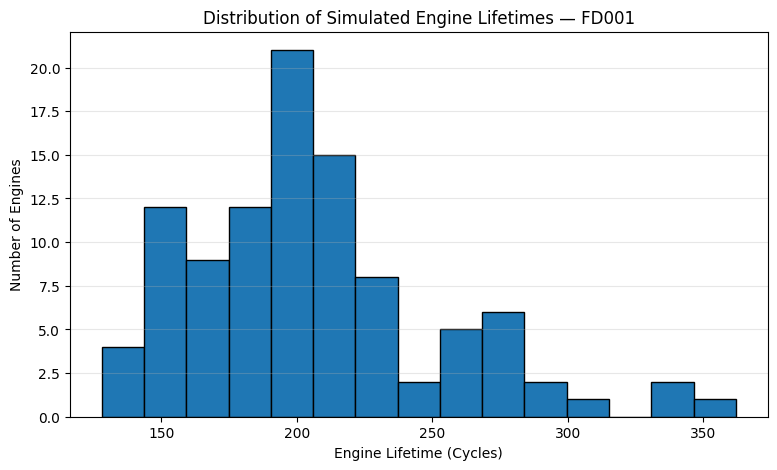

In [4]:

# One lifetime observation per engine
engine_lifetimes = train.groupby("engine_id")["cycle"].max()

print("Engine lifetime descriptive statistics:")
display(engine_lifetimes.describe())

plt.figure(figsize=(9, 5))

plt.hist(
    engine_lifetimes,
    bins=15,
    edgecolor="black"
)

plt.xlabel("Engine Lifetime (Cycles)")
plt.ylabel("Number of Engines")
plt.title("Distribution of Simulated Engine Lifetimes — FD001")
plt.grid(axis="y", alpha=0.3)

plt.show()



## 5. Sensor Variability & Correlations

Calculate the standard deviation of each sensor to identify measurements with little or no variation.

Nearly constant sensors may provide limited information for predicting engine degradation.


In [5]:

sensors = [f"sensor_{i}" for i in range(1, 22)]

# 1. Identify sensors with little or no variation
variability = train[sensors].std().sort_values()
display(variability)

# 2. Calculate correlations with RUL
correlations = (
    train[sensors + ["RUL"]]
    .corr()["RUL"]
    .drop("RUL")
    .sort_values(key=abs, ascending=False)
)

display(correlations)


sensor_1     0.000000e+00
sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_10    0.000000e+00
sensor_16    1.387812e-17
sensor_5     1.776400e-15
sensor_6     1.388985e-03
sensor_15    3.750504e-02
sensor_8     7.098548e-02
sensor_13    7.191892e-02
sensor_21    1.082509e-01
sensor_20    1.807464e-01
sensor_11    2.670874e-01
sensor_2     5.000533e-01
sensor_12    7.375534e-01
sensor_7     8.850923e-01
sensor_17    1.548763e+00
sensor_3     6.131150e+00
sensor_4     9.000605e+00
sensor_14    1.907618e+01
sensor_9     2.208288e+01
dtype: float64

sensor_11   -0.696228
sensor_4    -0.678948
sensor_12    0.671983
sensor_7     0.657223
sensor_15   -0.642667
sensor_21    0.635662
sensor_20    0.629428
sensor_2    -0.606484
sensor_17   -0.606154
sensor_3    -0.584520
sensor_8    -0.563968
sensor_13   -0.562569
sensor_9    -0.390102
sensor_14   -0.306769
sensor_6    -0.128348
sensor_1          NaN
sensor_5          NaN
sensor_10         NaN
sensor_16         NaN
sensor_18         NaN
sensor_19         NaN
Name: RUL, dtype: float64